# Exploración de datos LocalScore

Notebook para explorar el dump del benchmark [LocalScore](https://www.localscore.ai/) (inferencia de LLMs en hardware local).

**Base de datos:** `data/raw/localscore-09-24-2025.db`

## 1. Carga y esquema de la base

In [1]:
import sqlite3
import pandas as pd
from pathlib import Path

DB_PATH = Path("../data/raw/localscore-09-24-2025.db")
assert DB_PATH.exists(), f"No se encuentra {DB_PATH}"

conn = sqlite3.connect(DB_PATH)

In [2]:
# Tablas disponibles
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name",
    conn
)
print("Tablas:", list(tables["name"]))

Tablas: ['__drizzle_migrations', 'accelerator_model_performance_scores', 'accelerators', 'benchmark_runs', 'benchmark_systems', 'model_variants', 'models', 'runtimes', 'sqlite_sequence', 'test_results']


In [3]:
# Esquema de cada tabla
for table in tables["name"]:
    if table.startswith("__"):
        continue
    info = pd.read_sql_query(f"PRAGMA table_info({table})", conn)
    n = pd.read_sql_query(f"SELECT COUNT(*) as n FROM {table}", conn).iloc[0, 0]
    print(f"\n{table} ({n} filas)")
    print(info[["name", "type"]].to_string(index=False))


accelerator_model_performance_scores (1094 filas)
                 name    type
       accelerator_id INTEGER
     accelerator_name    TEXT
     accelerator_type    TEXT
accelerator_memory_gb    REAL
             model_id INTEGER
           model_name    TEXT
     model_variant_id INTEGER
  model_variant_quant    TEXT
       avg_prompt_tps    REAL
          avg_gen_tps    REAL
             avg_ttft    REAL
    performance_score    REAL

accelerators (500 filas)
        name    type
          id INTEGER
        name    TEXT
        type    TEXT
   memory_gb    REAL
manufacturer    TEXT
  created_at INTEGER

benchmark_runs (1556 filas)
             name    type
               id INTEGER
        system_id INTEGER
   accelerator_id INTEGER
 model_variant_id INTEGER
       runtime_id INTEGER
   avg_prompt_tps    REAL
      avg_gen_tps    REAL
      avg_ttft_ms    REAL
performance_score    REAL
       created_at INTEGER

benchmark_systems (653 filas)
          name    type
            id IN

## 2. Tabla principal: rendimiento por acelerador y modelo

`accelerator_model_performance_scores` agrupa métricas de inferencia por combinación (acelerador, modelo, variante/cuantización).

In [4]:
df = pd.read_sql_query(
    "SELECT * FROM accelerator_model_performance_scores",
    conn
)
df.shape

(1094, 12)

In [5]:
df.head(10)

,accelerator_id,accelerator_name,accelerator_type,accelerator_memory_gb,model_id,model_name,model_variant_id,model_variant_quant,avg_prompt_tps,avg_gen_tps,avg_ttft,performance_score
0,1,NVIDIA GeForce RTX 3090,GPU,24.00,1,Meta Llama 3.1 8B Instruct,1,Q4_K - Medium,3485.988798,93.331954,634.510636,925.318839
1,1,NVIDIA GeForce RTX 3090,GPU,24.00,2,Qwen2.5 14B Instruct,2,Q4_K - Medium,1987.767148,58.376564,644.778371,564.720648
2,1,NVIDIA GeForce RTX 3090,GPU,24.00,3,Llama 3.2 1B Instruct,3,Q4_K - Medium,13233.169735,248.625372,101.821645,3151.625982
3,4,Apple M1 Pro 8P+2E+16GPU,GPU,32.00,3,Llama 3.2 1B Instruct,3,Q4_K - Medium,1165.955519,77.239360,1036.503846,443.272452
4,5,AMD EPYC 7352 24-Core Processor (znver2),CPU,125.64,3,Llama 3.2 1B Instruct,3,Q4_K - Medium,265.810436,14.275531,5575.048065,87.964053
5,6,Apple M4 Max 12P+4E+40GPU,GPU,128.00,3,Llama 3.2 1B Instruct,3,Q4_K - Medium,3847.507827,183.472977,304.170130,1323.959318
6,7,NVIDIA GeForce RTX 4060 Ti,GPU,16.00,3,Llama 3.2 1B Instruct,3,Q4_K - Medium,9202.935720,209.292069,168.029946,2254.422108
7,8,Apple M4 Max 12P+4E,CPU,128.00,3,Llama 3.2 1B Instruct,3,Q4_K - Medium,679.710183,156.300001,1966.157426,378.054858
8,7,NVIDIA GeForce RTX 4060 Ti,GPU,16.00,1,Meta Llama 3.1 8B Instruct,1,Q4_K - Medium,2215.044659,48.186759,623.059349,555.312009
9,7,NVIDIA GeForce RTX 4060 Ti,GPU,16.00,2,Qwen2.5 14B Instruct,2,Q4_K - Medium,1244.191799,25.971384,1097.584769,308.761616


In [6]:
df.dtypes

accelerator_id             int64
accelerator_name             str
accelerator_type             str
accelerator_memory_gb    float64
model_id                   int64
model_name                   str
model_variant_id           int64
model_variant_quant          str
avg_prompt_tps           float64
avg_gen_tps              float64
avg_ttft                 float64
performance_score        float64
dtype: object

In [7]:
df.describe()

,accelerator_id,accelerator_memory_gb,model_id,model_variant_id,avg_prompt_tps,avg_gen_tps,avg_ttft,performance_score
count,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1094.000000,1.094000e+03,1094.000000
mean,637.588665,49.593272,144.119744,174.586837,1677.317301,57.191075,3.335505e+04,434.710221
std,454.045480,75.677976,338.863041,366.505859,3799.799974,269.482039,1.570523e+05,967.286419
min,1.000000,2.000000,1.000000,1.000000,0.434631,0.319833,3.767059e+01,0.355256
25%,239.000000,15.200000,2.000000,2.000000,60.171948,9.972420,9.037886e+02,30.207364
50%,586.500000,24.000000,3.000000,3.000000,283.790882,27.299509,5.130033e+03,118.887021
75%,1013.750000,59.400000,3.000000,123.250000,1496.495988,55.046968,2.327696e+04,438.185652
max,1556.000000,755.800000,1425.000000,1555.000000,40878.500629,6670.359747,3.413784e+06,15340.405861


In [8]:
df.isna().sum()

accelerator_id           0
accelerator_name         0
accelerator_type         0
accelerator_memory_gb    0
model_id                 0
model_name               0
model_variant_id         0
model_variant_quant      0
avg_prompt_tps           0
avg_gen_tps              0
avg_ttft                 0
performance_score        0
dtype: int64

## 3. Catálogos: modelos, aceleradores, variantes

In [9]:
models = pd.read_sql_query("SELECT * FROM models", conn)
print("Modelos (primeros 15):")
models.head(15)

Modelos (primeros 15):


,id,name,params,created_at
0,1,Meta Llama 3.1 8B Instruct,8030263296,2025-03-19 21:50:27
1,2,Qwen2.5 14B Instruct,14770033664,2025-03-19 21:53:38
2,3,Llama 3.2 1B Instruct,1498483200,2025-03-19 21:54:18
3,14,Gemma 3 4b It,4551187968,2025-03-24 17:13:26
4,20,Qwen2.5.1 Coder 7B Instruct,7615616512,2025-03-26 21:07:19
5,27,Ministral 8B Instruct 2410 TEST,8019808256,2025-03-27 23:46:56
6,28,Mistral Nemo Instruct 2407,12247782400,2025-03-27 23:50:06
7,29,Mistral Small 24B Instruct 2501,23572403200,2025-03-27 23:54:34
8,31,Gemma 3 1b It,1301875840,2025-03-28 17:22:05
9,179,DeepSeek R1 Distill Qwen 1.5B,1777088000,2025-03-30 20:25:26


In [10]:
accelerators = pd.read_sql_query("SELECT * FROM accelerators", conn)
print("Tipos de acelerador:", accelerators["type"].value_counts().to_dict())
print("\nEjemplos de aceleradores:")
accelerators.head(10)

Tipos de acelerador: {'CPU': 318, 'GPU': 182}

Ejemplos de aceleradores:


,id,name,type,memory_gb,manufacturer,created_at
0,1,NVIDIA GeForce RTX 3090,GPU,24.00,NVIDIA,2025-03-19 21:50:27
1,4,Apple M1 Pro 8P+2E+16GPU,GPU,32.00,Apple,2025-03-19 22:06:18
2,5,AMD EPYC 7352 24-Core Processor (znver2),CPU,125.64,AMD,2025-03-19 22:07:11
3,6,Apple M4 Max 12P+4E+40GPU,GPU,128.00,Apple,2025-03-19 22:13:24
4,7,NVIDIA GeForce RTX 4060 Ti,GPU,16.00,NVIDIA,2025-03-19 22:16:35
5,8,Apple M4 Max 12P+4E,CPU,128.00,Apple,2025-03-19 22:17:25
6,12,AMD Radeon RX 6650 XT,GPU,8.00,AMD,2025-03-19 22:54:01
7,15,NVIDIA GeForce RTX 4080,GPU,16.00,NVIDIA,2025-03-24 18:27:24
8,17,Apple M1 4P+4E+8GPU,GPU,8.00,Apple,2025-03-24 21:01:49
9,22,Tesla V100-PCIE-16GB,GPU,16.00,NVIDIA,2025-03-27 21:40:49


In [11]:
print("Variantes de cuantización en la tabla de scores:")
df["model_variant_quant"].value_counts()

Variantes de cuantización en la tabla de scores:


model_variant_quant
Q4_K - Medium      888
Q8_0                66
Q6_K                36
Q5_K - Medium       28
Q4_0                27
F16                 17
BF16                 9
Q2_K - Medium        7
Q4_K - Small         4
Q3_K - Medium        4
Q3_K - Large         4
IQ2_M - 2.7 bpw      1
Q5_K - Small         1
all F32              1
Q3_K - Small         1
Name: count, dtype: int64

## 4. Resúmenes por tipo de hardware y modelo

In [12]:
df.groupby("accelerator_type").agg(
    n_combinaciones=("accelerator_id", "count"),
    prompt_tps_media=("avg_prompt_tps", "mean"),
    gen_tps_media=("avg_gen_tps", "mean"),
    ttft_media=("avg_ttft", "mean"),
    score_medio=("performance_score", "mean"),
).round(2)

,n_combinaciones,prompt_tps_media,gen_tps_media,ttft_media,score_medio
accelerator_type,,,,,
CPU,570,273.15,43.10,61602.67,117.66
GPU,524,3204.75,72.52,2627.67,779.59


In [13]:
por_modelo = df.groupby("model_name").agg(
    n_configs=("model_id", "count"),
    gen_tps_media=("avg_gen_tps", "mean"),
    ttft_media=("avg_ttft", "mean"),
    score_medio=("performance_score", "mean"),
).round(2)
por_modelo.sort_values("score_medio", ascending=False).head(15)

,n_configs,gen_tps_media,ttft_media,score_medio
model_name,,,,
Raincandy U TinyStories 656K,3,4307.73,61.55,12395.58
Qwen2.5 0.5B Instruct,1,299.68,66.96,4470.18
Qwen2.5 1.5B Instruct,1,205.33,111.35,2745.94
Model Hf,1,68.10,114.71,1872.80
Phi 4 Mini Instruct,1,145.39,231.38,1515.14
Phi 3.5 Mini Instruct,1,131.03,288.40,1260.04
Qwen3-4B,1,116.80,298.40,1204.71
Qwen3 Mini Moe,1,85.11,270.99,1175.53
Gemma 3 1b It,7,77.40,1437.15,1144.90


## 5. Visualizaciones

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline

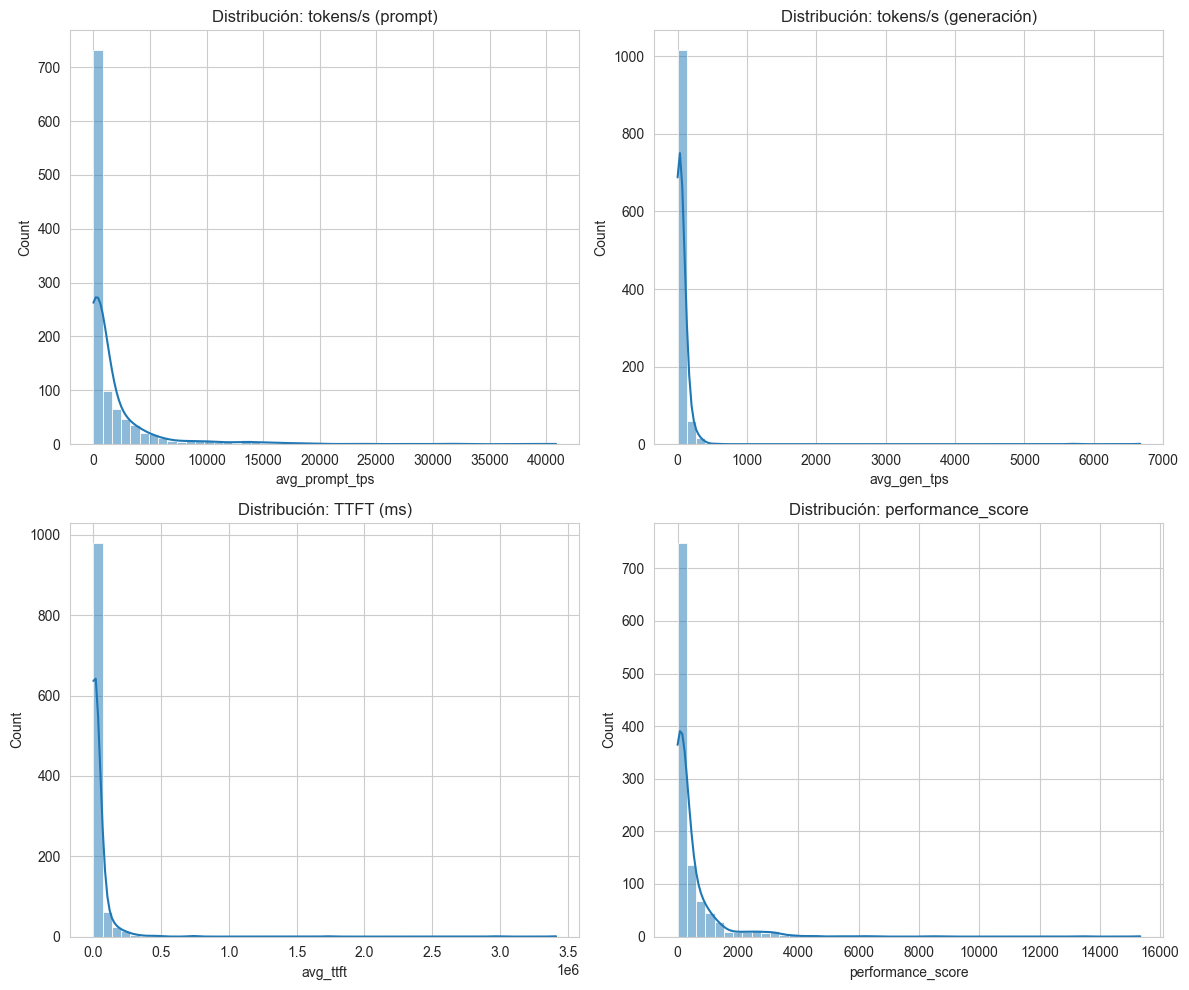

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(df["avg_prompt_tps"], bins=50, ax=axes[0, 0], kde=True)
axes[0, 0].set_title("Distribución: tokens/s (prompt)")

sns.histplot(df["avg_gen_tps"], bins=50, ax=axes[0, 1], kde=True)
axes[0, 1].set_title("Distribución: tokens/s (generación)")

sns.histplot(df["avg_ttft"], bins=50, ax=axes[1, 0], kde=True)
axes[1, 0].set_title("Distribución: TTFT (ms)")

sns.histplot(df["performance_score"], bins=50, ax=axes[1, 1], kde=True)
axes[1, 1].set_title("Distribución: performance_score")

plt.tight_layout()
plt.show()

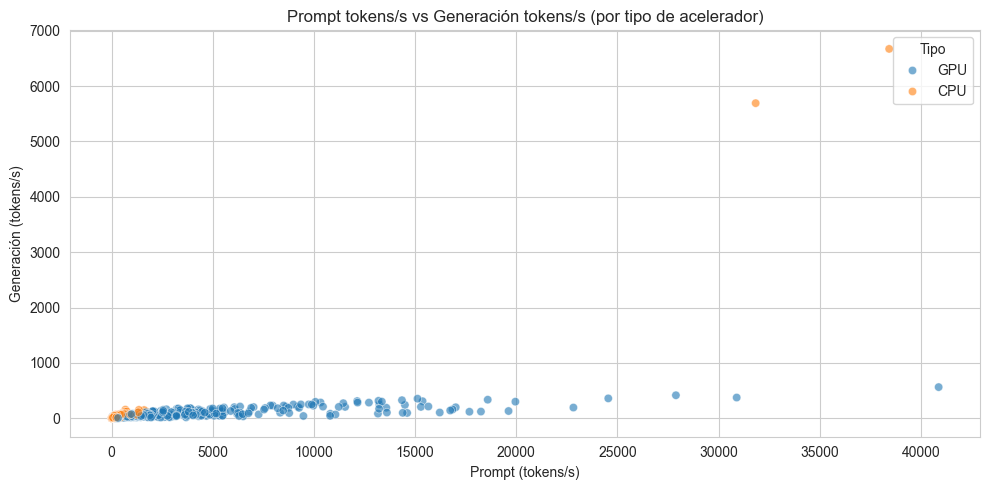

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="avg_prompt_tps",
    y="avg_gen_tps",
    hue="accelerator_type",
    alpha=0.6,
    ax=ax,
)
ax.set_title("Prompt tokens/s vs Generación tokens/s (por tipo de acelerador)")
ax.set_xlabel("Prompt (tokens/s)")
ax.set_ylabel("Generación (tokens/s)")
plt.legend(title="Tipo")
plt.tight_layout()
plt.show()

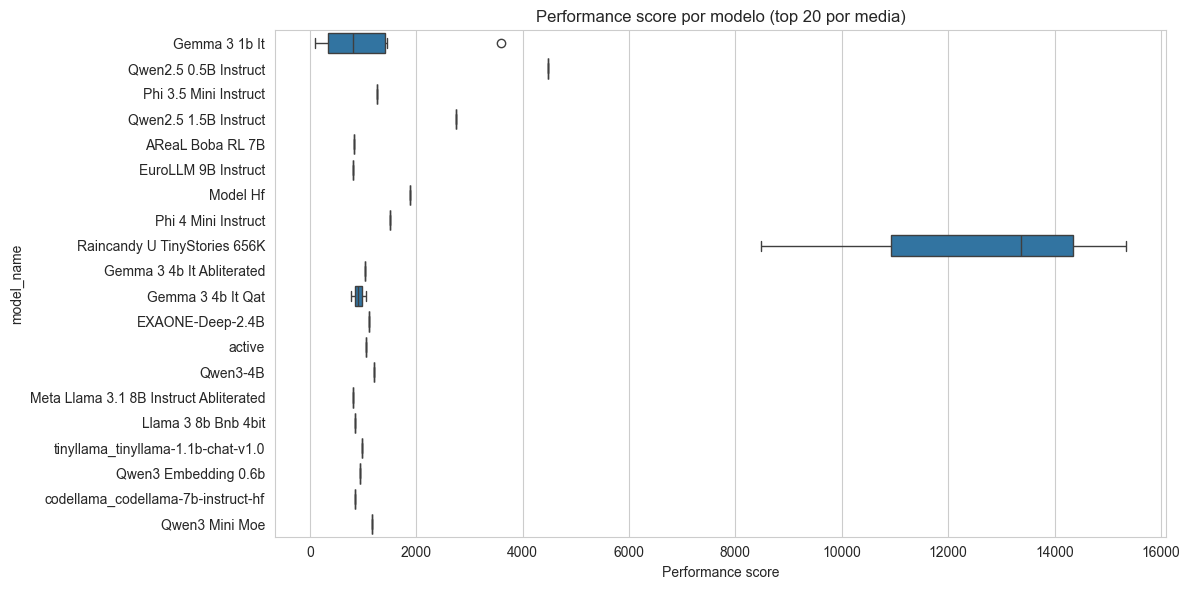

In [17]:
# Top modelos por score medio (ejemplo: hasta 20 modelos)
top_models = (
    df.groupby("model_name")["performance_score"]
    .mean()
    .sort_values(ascending=False)
    .head(20)
    .index.tolist()
)
df_top = df[df["model_name"].isin(top_models)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, y="model_name", x="performance_score", orient="h")
plt.title("Performance score por modelo (top 20 por media)")
plt.xlabel("Performance score")
plt.tight_layout()
plt.show()

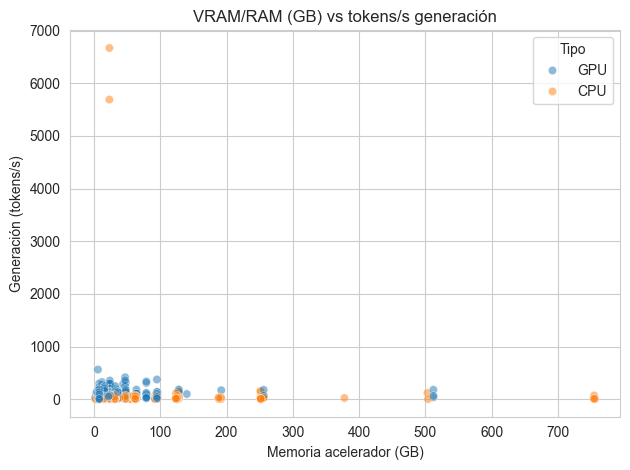

In [18]:
# Memoria del acelerador vs generación (tokens/s)
sns.scatterplot(
    data=df,
    x="accelerator_memory_gb",
    y="avg_gen_tps",
    hue="accelerator_type",
    alpha=0.5,
)
plt.title("VRAM/RAM (GB) vs tokens/s generación")
plt.xlabel("Memoria acelerador (GB)")
plt.ylabel("Generación (tokens/s)")
plt.legend(title="Tipo")
plt.tight_layout()
plt.show()

## 6. Consultas útiles para viabilidad

Ejemplo: configuraciones que superan un umbral mínimo de generación (tokens/s) o TTFT máximo.

In [19]:
MIN_GEN_TPS = 50   # tokens/s mínimo en generación
MAX_TTFT_MS = 500  # tiempo al primer token máximo (ms)

viables = df[(df["avg_gen_tps"] >= MIN_GEN_TPS) & (df["avg_ttft"] <= MAX_TTFT_MS)]
print(f"Combinaciones que cumplen gen_tps >= {MIN_GEN_TPS} y ttft <= {MAX_TTFT_MS} ms: {len(viables)}")
viables[["accelerator_name", "model_name", "model_variant_quant", "avg_gen_tps", "avg_ttft", "performance_score"]].head(15)

Combinaciones que cumplen gen_tps >= 50 y ttft <= 500 ms: 165


,accelerator_name,model_name,model_variant_quant,avg_gen_tps,avg_ttft,performance_score
2,NVIDIA GeForce RTX 3090,Llama 3.2 1B Instruct,Q4_K - Medium,248.625372,101.821645,3151.625982
5,Apple M4 Max 12P+4E+40GPU,Llama 3.2 1B Instruct,Q4_K - Medium,183.472977,304.170130,1323.959318
6,NVIDIA GeForce RTX 4060 Ti,Llama 3.2 1B Instruct,Q4_K - Medium,209.292069,168.029946,2254.422108
13,NVIDIA GeForce RTX 4060 Ti,Gemma 3 4b It,Q4_K - Medium,74.417917,263.836834,1112.786024
14,NVIDIA GeForce RTX 4080,Llama 3.2 1B Instruct,Q4_K - Medium,241.030405,130.066824,3133.389120
17,Tesla V100-PCIE-16GB,Llama 3.2 1B Instruct,Q4_K - Medium,248.261273,135.303754,2545.026862
18,NVIDIA GeForce GTX 1070 Ti,Llama 3.2 1B Instruct,Q4_K - Medium,115.766678,440.519248,921.781309
19,NVIDIA RTX A5000,Llama 3.2 1B Instruct,Q4_K - Medium,310.165891,110.423487,3242.389560
20,NVIDIA RTX A5000,Ministral 8B Instruct 2410 TEST,Q4_K - Medium,86.578680,457.132578,811.028542
23,NVIDIA GeForce RTX 3090,Gemma 3 1b It,Q4_K - Medium,198.696039,72.856561,3593.062749


In [20]:
conn.close()